# Target Frenzy – Player Skill Classifier (IS Feature 3)

**Machine learning type:** unsupervised learning, **K-Means clustering**.

Each finished game is uploaded by the ESP32 to Supabase. This notebook groups players by **how they play**
into three skill levels: **Beginner**, **Sharpshooter** and **Pro**. The resulting group centers are copied
into the ESP32 code, so every new player gets a skill label on the dashboard right after their game.

**Steps:** load data → clean → build features → scale → choose *k* (elbow + silhouette) → train → label → export to ESP32.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RANDOM_STATE = 42   # fixed so the results are the same every run

## 2. Load the game data

Export it from Supabase: **Table Editor → scores → Export → Export as CSV**.
In Colab, run this cell and choose the downloaded `scores_rows.csv` when asked.

In [2]:
import os
CSV = "scores_rows.csv"
if not os.path.exists(CSV):
    try:
        from google.colab import files          # only exists in Google Colab
        uploaded = files.upload()               # pick scores_rows.csv
        CSV = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError("Put scores_rows.csv next to this notebook.")

raw = pd.read_csv(CSV)
print(f"{len(raw)} games in the file")
raw.tail()

72 games in the file


,id,created_at,game_id,player_name,score,round1,round2,round3,shots,hits,shots_r1,shots_r2,shots_r3,hits_r1,hits_r2,hits_r3,avg_reaction_ms,targets_missed
67,68,2026-11-24 19:47:54.858047+00,bf0bf49b,LAUVEY,1725,400,225,1100,113,22,31,40,42,8,3,11,814,21
68,69,2026-11-24 19:49:27.515526+00,a7ff67e9,POE,1225,450,675,100,114,19,34,40,40,9,9,1,795,24
69,70,2026-11-24 19:50:43.718127+00,cbf6a1c7,YANG,1100,250,450,400,108,15,32,34,42,5,6,4,854,28
70,71,2026-11-24 19:52:36.147024+00,77535bf3,YUNI,975,250,525,200,119,14,38,41,40,5,7,2,865,27
71,72,2026-11-24 19:54:18.746725+00,ce9964b2,IVY,1525,450,375,700,116,21,34,40,42,9,5,7,940,25


## 3. Clean the data

Cleaning rules:
1. **Remove tests where nobody played**: games with **0 shots**.
2. **Keep only games with the full data**: games played after the 19 November update have reaction time and
   per-round data (`avg_reaction_ms > 0`). Older games lack these features.
3. A game with 0 points **but** shots fired is a real beginner, so it stays.

In [3]:
no_shots   = raw["shots"] == 0
old_format = raw["avg_reaction_ms"] == 0
data = raw[~no_shots & ~old_format].copy()

print(f"Removed {no_shots.sum()} games with no shots (tests)")
print(f"Removed {(~no_shots & old_format).sum()} older games without reaction-time data")
print(f"Usable games: {len(data)}  |  different player names: {data['player_name'].nunique()}")

Removed 1 games with no shots (tests)
Removed 31 older games without reaction-time data
Usable games: 40  |  different player names: 40


## 4. Features

Three numbers describe how a player plays:

| Feature | Formula | Meaning |
| --- | --- | --- |
| `hit_rate` | hits ÷ (hits + targets missed) × 100 | How many of the targets that popped up the player knocked down |
| `shot_accuracy` | hits ÷ shots × 100 | How many shots actually hit (trigger control) |
| `reaction_ms` | average time from "target up" to "hit" | How fast the player reacts |

Score is left out on purpose: it mostly repeats the hit count, and the three features above explain **why** a score is high or low.

In [4]:
data["hit_rate"]      = 100 * data["hits"] / (data["hits"] + data["targets_missed"])
data["shot_accuracy"] = 100 * data["hits"] / data["shots"]
data["reaction_ms"]   = data["avg_reaction_ms"]

FEATURES = ["hit_rate", "shot_accuracy", "reaction_ms"]
data[FEATURES + ["score"]].describe().round(1)

,hit_rate,shot_accuracy,reaction_ms,score
count,40.0,40.0,40.0,40.0
mean,37.5,15.1,866.2,1225.6
std,11.4,6.4,157.9,470.7
min,19.4,5.6,569.0,525.0
25%,28.2,9.5,763.2,862.5
50%,36.9,15.0,831.5,1212.5
75%,44.7,18.6,919.5,1600.0
max,62.7,30.0,1266.0,2350.0


## 5. Scale the features

The features use different units (percent vs milliseconds). Without scaling, reaction time (hundreds of ms) would
dominate the distance K-Means uses. `StandardScaler` turns each feature into *z-scores* (mean 0, standard deviation 1).

In [5]:
scaler = StandardScaler()
X = scaler.fit_transform(data[FEATURES])
pd.DataFrame({"mean": scaler.mean_, "std": scaler.scale_}, index=FEATURES).round(2)

,mean,std
hit_rate,37.53,11.30
shot_accuracy,15.15,6.35
reaction_ms,866.22,155.93


## 6. Choose the number of groups (k)

* **Elbow method**: inertia (how spread out the groups are) for k = 1–8. Look for the bend.
* **Silhouette score**: −1 to 1, higher means better-separated groups.

We also want groups we can **name** for players, so we check that **k = 3** is a reasonable choice.

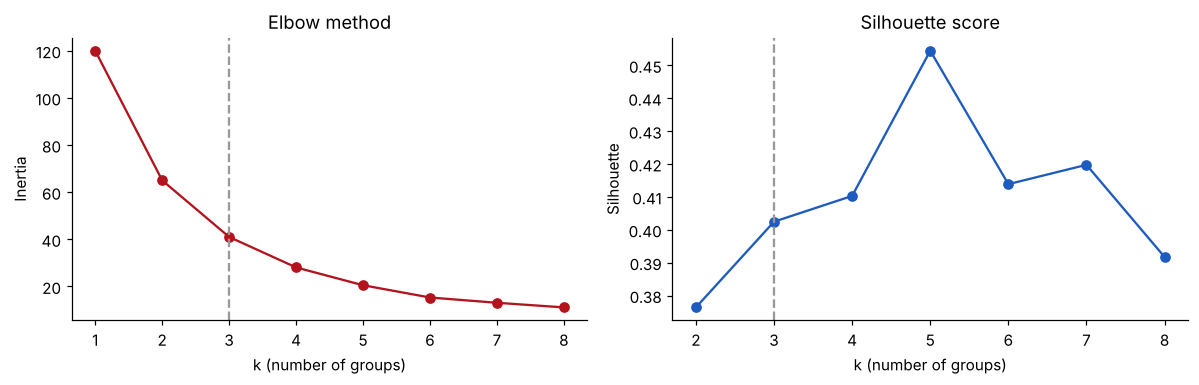

k=2: silhouette 0.376
k=3: silhouette 0.402
k=4: silhouette 0.410
k=5: silhouette 0.454
k=6: silhouette 0.414
k=7: silhouette 0.420
k=8: silhouette 0.392


In [6]:
ks = range(1, 9)
inertia, sil = [], {}
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    inertia.append(km.inertia_)
    if k >= 2:
        sil[k] = silhouette_score(X, km.labels_)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(list(ks), inertia, "o-", color="#b3131d")
ax[0].axvline(3, ls="--", color="#999"); ax[0].set(title="Elbow method", xlabel="k (number of groups)", ylabel="Inertia")
ax[1].plot(list(sil), list(sil.values()), "o-", color="#1d5bbf")
ax[1].axvline(3, ls="--", color="#999"); ax[1].set(title="Silhouette score", xlabel="k (number of groups)", ylabel="Silhouette")
plt.tight_layout(); plt.savefig("fig_elbow_silhouette.png", dpi=200, bbox_inches="tight"); plt.show()

for k, s in sil.items():
    print(f"k={k}: silhouette {s:.3f}")

## 7. Train K-Means with k = 3 and name the groups

In [7]:
K = 3
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X)
data["cluster"] = kmeans.labels_
sil3 = silhouette_score(X, kmeans.labels_)
print(f"Silhouette score (k=3): {sil3:.3f}")

# Name the clusters by overall skill: better hit rate and accuracy, faster (lower) reaction = more skilled
centers_z = kmeans.cluster_centers_                       # in scaled units
skill = centers_z[:, 0] + centers_z[:, 1] - centers_z[:, 2]
order = np.argsort(skill)                                 # weakest -> strongest
NAMES = ["Beginner", "Sharpshooter", "Pro"]
name_of = {int(c): NAMES[i] for i, c in enumerate(order)}
data["skill"] = data["cluster"].map(name_of)

centers = pd.DataFrame(scaler.inverse_transform(centers_z), columns=FEATURES)
centers["skill"] = [name_of[c] for c in range(K)]
centers["players"] = data["cluster"].value_counts().sort_index().values
centers = centers.set_index("skill").loc[NAMES].round(1)
centers

Silhouette score (k=3): 0.402


,hit_rate,shot_accuracy,reaction_ms,players
skill,,,,
Beginner,27.6,10.5,1147.7,7
Sharpshooter,31.1,11.3,808.7,17
Pro,48.7,21.3,804.2,16


## 8. See the groups

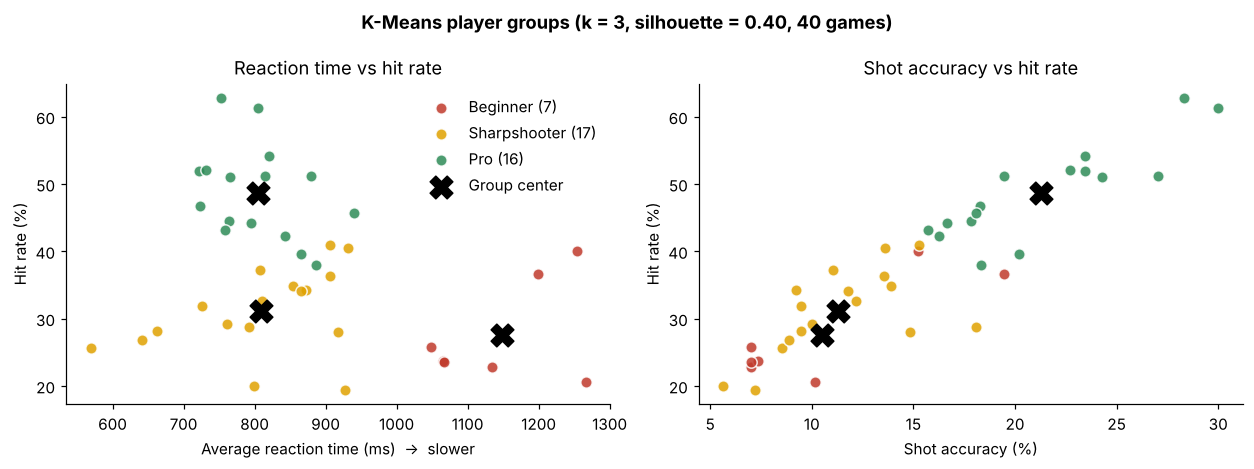

In [8]:
COL = {"Beginner": "#c0392b", "Sharpshooter": "#e0a100", "Pro": "#2e8b57"}
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.3))
for name in NAMES:
    g = data[data["skill"] == name]
    ax[0].scatter(g["reaction_ms"], g["hit_rate"], s=55, color=COL[name], label=f"{name} ({len(g)})", alpha=.85, edgecolor="white")
    ax[1].scatter(g["shot_accuracy"], g["hit_rate"], s=55, color=COL[name], label=name, alpha=.85, edgecolor="white")
ax[0].scatter(centers["reaction_ms"], centers["hit_rate"], marker="X", s=220, color="black", label="Group center")
ax[1].scatter(centers["shot_accuracy"], centers["hit_rate"], marker="X", s=220, color="black")
ax[0].set(title="Reaction time vs hit rate", xlabel="Average reaction time (ms)  →  slower", ylabel="Hit rate (%)")
ax[1].set(title="Shot accuracy vs hit rate", xlabel="Shot accuracy (%)", ylabel="Hit rate (%)")
ax[0].legend(frameon=False)
fig.suptitle(f"K-Means player groups (k = 3, silhouette = {sil3:.2f}, {len(data)} games)", fontweight="bold")
plt.tight_layout(); plt.savefig("fig_clusters.png", dpi=200, bbox_inches="tight"); plt.show()

In [9]:
table = data[["player_name", "score", "hit_rate", "shot_accuracy", "reaction_ms", "skill"]].round(1)
table.sort_values("score", ascending=False).reset_index(drop=True)

,player_name,score,hit_rate,shot_accuracy,reaction_ms,skill
0,RICK,2350,62.7,28.3,753,Pro
1,ED,2275,61.2,30.0,805,Pro
2,ADAM,1875,54.2,23.4,820,Pro
3,HFHH1HLOUIE,1825,52.0,23.4,722,Pro
4,UPLOAD TEST,1800,51.0,24.3,766,Pro
5,CHRIS,1775,52.1,22.7,732,Pro
6,RHAM,1750,39.7,20.2,866,Pro
7,LAUVEY,1725,51.2,19.5,814,Pro
8,ACE,1650,51.1,27.1,879,Pro
9,PLAYER1,1600,37.9,18.3,887,Pro


## 9. Classify a new game (exactly what the ESP32 will do)

Scale the new game's three features with the same mean and standard deviation, measure the distance to each group
center, and pick the nearest one.

In [10]:
def classify(hit_rate, shot_accuracy, reaction_ms):
    z = (np.array([hit_rate, shot_accuracy, reaction_ms]) - scaler.mean_) / scaler.scale_
    d = np.linalg.norm(centers_z - z, axis=1)
    return name_of[int(np.argmin(d))], d.round(2)

for example in [(25, 8, 1100), (38, 15, 850), (55, 25, 700)]:
    print(example, "->", classify(*example))

(25, 8, 1100) -> ('Beginner', array([3.52, 2.01, 0.54]))
(38, 15, 850) -> ('Sharpshooter', array([1.4 , 0.88, 2.24]))
(55, 25, 700) -> ('Pro', array([1.05, 3.1 , 4.4 ]))


## 10. Export for the ESP32

Copy the printed block into `sketch.ino` (section **IS Feature 3**). The ESP32 then labels each new player on its own,
with no internet needed.

In [11]:
ordered = [int(c) for c in order]   # Beginner, Sharpshooter, Pro
fmt = lambda a: ", ".join(f"{v:.4f}" for v in a)
print("// ---- generated by the Target Frenzy K-Means notebook ----")
print(f"const float KM_MEAN[3]  = {{{fmt(scaler.mean_)}}};   // hit_rate, shot_accuracy, reaction_ms")
print(f"const float KM_STD[3]   = {{{fmt(scaler.scale_)}}};")
print("const float KM_CENTER[3][3] = {   // scaled centers: Beginner, Sharpshooter, Pro")
for c in ordered:
    print(f"  {{{fmt(centers_z[c])}}},")
print("};")
print('const char* KM_NAME[3] = {"Beginner", "Sharpshooter", "Pro"};')

data.to_csv("players_with_skill.csv", index=False)
print("\nSaved players_with_skill.csv, fig_elbow_silhouette.png and fig_clusters.png")

// ---- generated by the Target Frenzy K-Means notebook ----
const float KM_MEAN[3]  = {37.5300, 15.1484, 866.2250};   // hit_rate, shot_accuracy, reaction_ms
const float KM_STD[3]   = {11.2972, 6.3532, 155.9312};
const float KM_CENTER[3][3] = {   // scaled centers: Beginner, Sharpshooter, Pro
  {-0.8820, -0.7360, 1.8052},
  {-0.5687, -0.6011, -0.3689},
  {0.9901, 0.9607, -0.3979},
};
const char* KM_NAME[3] = {"Beginner", "Sharpshooter", "Pro"};

Saved players_with_skill.csv, fig_elbow_silhouette.png and fig_clusters.png
